# 01 · Os documentos de entrada

**Desafio 1 — BRACIS 2026 / Jusbrasil · verificação de citações jurídicas em pareceres de IA**

Este notebook olha só para `data/txt/`: as 26 peças jurídicas sintéticas que o
sistema recebe como entrada. A pergunta que ele responde é *o que existe no texto
antes de qualquer decisão de classificação* — como as peças são montadas, onde as
citações moram, o que é armadilha e como o ruído do nível 2 se manifesta.

Os outros notebooks da série:

| Notebook | Base |
|---|---|
| `01_eda_documentos.ipynb` | os 26 `.txt` de entrada ← *você está aqui* |
| `02_eda_base_canonica.ipynb` | o SQLite `desafio1_bracis.db` |
| `03_eda_gabarito.ipynb` | o `goldenset.csv` |
| `04_analise_integrada.ipynb` | a relação entre os três, e um baseline de resolução |

> **Pré-requisito:** `uv sync` na raiz do repositório para instalar o grupo `notebooks`.

In [2]:
import sys, re, collections
from pathlib import Path

# permite importar eda_utils tanto rodando de notebooks/ ou da raiz
for base in [Path.cwd(), *Path.cwd().parents]:
    if (base / "src" / "eda_utils.py").exists():
        sys.path.insert(0, str(base / "src"))
        break

import pandas as pd
import matplotlib.pyplot as plt
import eda_utils as u

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 160)
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print("raiz do projeto:", u.raiz_projeto())

raiz do projeto: /work


In [3]:
docs = u.carregar_documentos()
print(f"{len(docs)} documentos carregados")
print("exemplo de identificador:", list(docs)[0])

26 documentos carregados
exemplo de identificador: gen_n1_001


## 1. Inventário

Vinte e seis peças, treze por nível. O nível está no nome do arquivo (`gen_n1_*`,
`gen_n2_*`) e define o peso na nota: 1× para o nível 1, 2× para o nível 2.

In [4]:
inv = pd.DataFrame([
    {"documento_id": d,
     "nivel": u.nivel(d),
     "chars": len(t),
     "linhas": t.count(chr(10)) + 1,
     "abertura": t.split(chr(10))[0][:52]}
    for d, t in sorted(docs.items())
])
inv

,documento_id,nivel,chars,linhas,abertura
0,gen_n1_001,1,3498,64,DEFENSORIA PÚBLICA DA UNIÃO
1,gen_n1_002,1,3563,65,PODER JUDICIÁRIO
2,gen_n1_003,1,3411,62,EGRÉGIO SUPERIOR TRIBUNAL DE JUSTIÇA
3,gen_n1_004,1,2880,59,MINISTÉRIO PÚBLICO MILITAR
4,gen_n1_005,1,3375,62,EGRÉGIO SUPERIOR TRIBUNAL DE JUSTIÇA
5,gen_n1_006,1,3309,62,MINISTÉRIO PÚBLICO ELEITORAL
6,gen_n1_007,1,3270,60,MEMORIAL
7,gen_n1_008,1,3466,64,PODER JUDICIÁRIO
8,gen_n1_009,1,3887,67,EXCELENTÍSSIMO SENHOR DOUTOR DESEMBARGADOR RELATOR D
9,gen_n1_010,1,3485,62,MEMORIAL


       count    mean     min     50%     max
nivel                                       
1       13.0  3390.0  2880.0  3411.0  3887.0
2       13.0  3277.0  2977.0  3265.0  3712.0


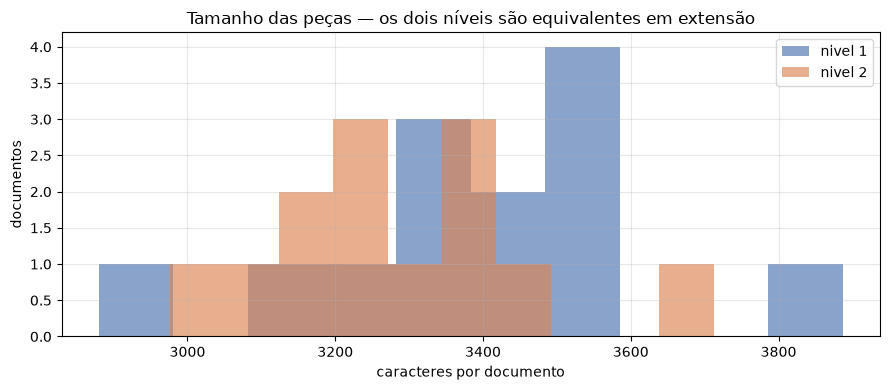

In [5]:
print(inv.groupby("nivel")["chars"].describe()[["count", "mean", "min", "50%", "max"]].round(0))

fig, ax = plt.subplots()
for niv, cor in [(1, "#4C72B0"), (2, "#DD8452")]:
    ax.hist(inv.loc[inv.nivel == niv, "chars"], bins=10, alpha=0.65,
            label=f"nivel {niv}", color=cor)
ax.set_xlabel("caracteres por documento"); ax.set_ylabel("documentos")
ax.set_title("Tamanho das peças — os dois níveis são equivalentes em extensão")
ax.legend(); plt.tight_layout(); plt.show()

As duas metades do conjunto têm o mesmo porte (média em torno de 3,3 mil
caracteres, entre 2,9 e 3,9 mil). Isso é intencional: o nível 2 não é "mais
difícil por ser maior", a dificuldade está toda na superfície do texto. Também
significa que qualquer diferença de desempenho entre níveis é atribuível à
normalização, não ao volume.

## 2. Anatomia de uma peça

Os documentos são gerados a partir de um molde comum: cabeçalho institucional,
partes, corpo dividido em seções numeradas em algarismos romanos. Reconhecer esse
molde é o que separa cabeçalho (cheio de distratores) de corpo (onde moram as
citações).

In [6]:
print(docs["gen_n1_005"][:900])

EGRÉGIO SUPERIOR TRIBUNAL DE JUSTIÇA

Autos nº 1051967-37.2016.3.02.7661
Recorrente: ROBERTO CARVALHO PIRES
Recorrido: MARIA APARECIDA FONTES

CONTRARRAZÕES AO RECURSO ESPECIAL

MARIA APARECIDA FONTES, por seu procurador infra-assinado (OAB/SP 193771), vem, tempestivamente,
apresentar suas CONTRARRAZÕES ao recurso especial interposto pela parte adversa, requerendo,
desde logo, o não conhecimento do apelo nobre pelos fundamentos a seguir alinhavados.


É de rigor, portanto, o acolhimento da tese ora sustentada. Merece registro a jurisprudência
pacífica desta Corte, invocada desde a peça de defesa. Antes de avançar, convém delimitar o
objeto da irresignação. A propósito, veja-se os precedentes desta Casa em situações análogas,
que bem ilustra a orientação dominante. Com efeito, a controvérsia posta nos autos não é nova.
Cumpre destacar o AgInt no REsp 1.599.910/PR, cuja ratio decidendi se 


In [7]:
secoes = collections.Counter()
for t in docs.values():
    for m in re.finditer(r"^([IVX]+\s*[–—-]\s*[A-ZÀ-Ú][A-ZÀ-Ú \t]{3,60})$", t, re.M):
        secoes[re.sub(r"\s+", " ", m.group(1)).strip()] += 1

pd.DataFrame(secoes.most_common(), columns=["seção", "documentos"]).head(12)

,seção,documentos
0,II — DO DIREITO APLICÁVEL,25
1,IV — DA IMPOSSIBILIDADE DE REEXAME FÁTICO,25
2,I — DA CONTROVÉRSIA,24
3,III — DOS PRECEDENTES INVOCADOS,24
4,I — RELATÓRIO,1
5,II — DA CONTROVÉRSIA,1
6,III — DO DIREITO APLICÁVEL,1
7,IV — DOS PRECEDENTES INVOCADOS,1
8,V — DA IMPOSSIBILIDADE DE REEXAME FÁTICO,1


nivel             1  2
materia               
cível             1  1
eleitoral         2  2
federal           1  3
militar           2  2
não identificada  5  3
trabalhista       2  2


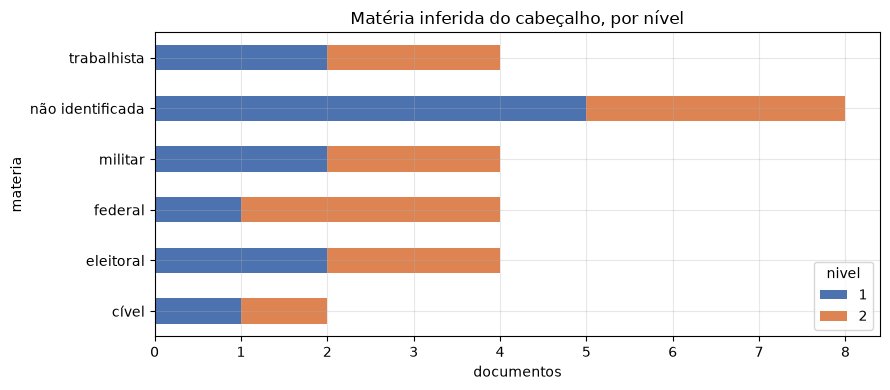

In [8]:
def materia(texto):
    cab = texto[:400].upper()
    for chave, rotulo in [("TRABALHO", "trabalhista"), ("ELEITORAL", "eleitoral"),
                          ("MILITAR", "militar"), ("CRIMINAL", "penal"),
                          ("CÍVEL", "cível"), ("FEDERAL", "federal")]:
        if chave in cab:
            return rotulo
    return "não identificada"

inv["materia"] = [materia(docs[d]) for d in inv.documento_id]
tab = pd.crosstab(inv.materia, inv.nivel)
print(tab)

tab.plot(kind="barh", stacked=True, color=["#4C72B0", "#DD8452"])
plt.title("Matéria inferida do cabeçalho, por nível"); plt.xlabel("documentos")
plt.tight_layout(); plt.show()

Cada peça tem uma matéria coerente que amarra cabeçalho, tribunais citados e
normas invocadas — um agravo trabalhista não cita apelação da Justiça Militar.
Isso é uma **restrição explorável**: a matéria detectada no cabeçalho restringe
os tribunais plausíveis para as citações daquele documento, e serve como filtro
de desempate quando a busca devolve candidatos de tribunais diferentes.

## 3. Distratores

O cabeçalho é armadilha por construção: ele contém números que *parecem* citação
e não são. Número dos autos do próprio documento em formato CNJ, protocolo,
inscrição na OAB, `fls. 234/567`, valor da causa. Extrair qualquer um deles é
falso positivo puro.

In [9]:
padroes = {
    "CNJ (autos do próprio doc)": r"(?:Autos|Processo)\s*n[º°o.]?\s*[\d.\-]{15,}",
    "OAB":            r"OAB[/\s][A-Z]{2}\s*\d+",
    "Protocolo":      r"Protocolo\s*n[º°o.]?\s*[\d./-]+",
    "fls.":           r"fls?\.\s*\d+(?:/\d+)?",
    "Valor da causa": r"[Vv]alor da causa[^\n]{0,40}",
    "Memorial/Parecer nº": r"(?:Memorial|Parecer)[^\n]{0,18}n[º°o.]?\s*[\d./-]+",
}
linhas = []
for nome, p in padroes.items():
    rx = re.compile(p)
    ocor = sum(len(rx.findall(t)) for t in docs.values())
    ndocs = sum(1 for t in docs.values() if rx.search(t))
    pos = [m.start() for t in docs.values() for m in rx.finditer(t)]
    linhas.append({"distrator": nome, "ocorrências": ocor, "documentos": ndocs,
                   "offset mediano": int(sorted(pos)[len(pos)//2]) if pos else None})
pd.DataFrame(linhas)

,distrator,ocorrências,documentos,offset mediano
0,CNJ (autos do próprio doc),25,25,68
1,OAB,5,5,263
2,Protocolo,6,6,190
3,fls.,31,26,1356
4,Valor da causa,2,2,215
5,Memorial/Parecer nº,1,1,146


números em formato CNJ no corpus: 38


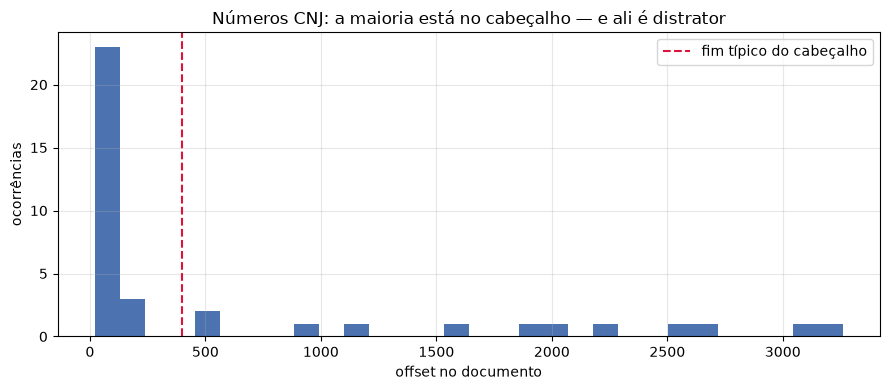

In [10]:
CNJ = re.compile(r"\d{7}-\d{2}\.\d{4}\.\d\.\d{2}\.\d{4}")
pos_cnj = sorted(m.start() for t in docs.values() for m in CNJ.finditer(t))
print(f"números em formato CNJ no corpus: {len(pos_cnj)}")

plt.hist(pos_cnj, bins=30, color="#4C72B0")
plt.axvline(400, color="crimson", ls="--", label="fim típico do cabeçalho")
plt.xlabel("offset no documento"); plt.ylabel("ocorrências")
plt.title("Números CNJ: a maioria está no cabeçalho — e ali é distrator")
plt.legend(); plt.tight_layout(); plt.show()

A distinção que o desafio cobra é **posicional**: o número CNJ no cabeçalho é o
processo *do próprio documento* e é distrator; o mesmo formato no corpo do texto
é referência a *outro* processo e é citação. O histograma mostra os dois modos
com clareza — uma concentração densa perto do offset zero e uma cauda espalhada
pelo corpo.

Note que `fls.` aparece em todos os 26 documentos: é o distrator mais frequente,
e o mais fácil de eliminar por regra. Já o CNJ exige a decisão de posição.

## 4. Vocabulário das citações

Antes de qualquer modelo, vale saber quantas formas de superfície o corpus usa
para nomear uma classe processual. É essa lista que um extrator baseado em regra
precisa cobrir — e é ela que explode no nível 2.

In [11]:
CLASSES = (r"AgRg|AgInt|AREsp|AgREsp|AREspEI|REspe|REsp|R\.?\s?Esp\.?|RHC|HC|RE\b|Rcl|RCL|"
           r"Reclamação|Recl\.|Súmula|Súm\.|5úmula|APL|RSE|EDcl|EDs|ED-|ARR|RR-|"
           r"AgARR|R-Rp|AR\b|Recurso Especial|Recurso Ordinário|Recurso em Habeas Corpus|"
           r"Agravo em Recurso Especial|Recurso de Revista")
rx = re.compile(CLASSES)

por_nivel = {1: collections.Counter(), 2: collections.Counter()}
for d, t in docs.items():
    for m in rx.finditer(t):
        por_nivel[u.nivel(d)][m.group(0)] += 1

voc = pd.DataFrame({"nivel 1": pd.Series(por_nivel[1]), "nivel 2": pd.Series(por_nivel[2])}).fillna(0).astype(int)
voc["total"] = voc.sum(axis=1)
voc.sort_values("total", ascending=False).head(25)

,nivel 1,nivel 2,total
APL,16,16,32
AgInt,10,10,20
Rcl,15,3,18
Reclamação,6,9,15
REsp,11,2,13
Súmula,6,3,9
ED-,4,5,9
EDcl,2,6,8
Recurso Especial,3,4,7
RR-,4,3,7


A cauda é longa e assimétrica entre os níveis: formas como `R.Esp.`, `Recl.` e
`5úmula` só existem no nível 2. Um extrator treinado apenas nas formas do nível 1
perde exatamente onde o peso da nota é 2×.

## 5. O ruído do nível 2

A documentação descreve o ruído como confusões de OCR (`0↔O`, `1↔l`, `5↔S`,
`m↔rn`), variação de abreviação, formatação do número, separador de UF e quebras
de linha no meio do identificador. Vale medir o tamanho real disso.

In [12]:
vocab = {}
for niv in (1, 2):
    c = collections.Counter()
    for d, t in docs.items():
        if u.nivel(d) == niv:
            for w in re.findall(r"[A-Za-zÀ-ÿ]{4,}", t):
                c[w.lower()] += 1
    vocab[niv] = c

so_n2 = [w for w in vocab[2] if w not in vocab[1]]
recuperaveis = []
for w in so_n2:
    for a, b in [("rn", "m"), ("l", "i"), ("c", "e"), ("i", "l")]:
        if a in w and w.replace(a, b) in vocab[1]:
            recuperaveis.append({"nivel 2": w, "forma limpa": w.replace(a, b), "regra": f"{a} -> {b}"})
            break

print(f"tipos de palavra exclusivos do nível 2: {len(so_n2)}")
print(f"recuperáveis por substituição de um par: {len(recuperaveis)}")
pd.DataFrame(recuperaveis).head(24)

tipos de palavra exclusivos do nível 2: 187
recuperáveis por substituição de um par: 47


,nivel 2,forma limpa,regra
0,assirn,assim,rn -> m
1,matérla,matéria,l -> i
2,honorárlos,honorários,l -> i
3,mesrna,mesma,rn -> m
4,lnsurge,insurge,l -> i
5,fundarnento,fundamento,rn -> m
6,seguirnento,seguimento,rn -> m
7,origcm,origem,c -> e
8,regimc,regime,c -> e
9,descnvolvido,desenvolvido,c -> e


In [13]:
quebras = collections.Counter()
for d, t in docs.items():
    # quebra de linha logo depois de "nº" ou no meio de um número
    quebras[u.nivel(d)] += len(re.findall(r"n[º°o.]?\s*\n\s*\d", t))
    quebras[u.nivel(d)] += len(re.findall(r"\d\s*\n\s*\d", t))
print("quebras de linha dentro de identificadores, por nível:", dict(quebras))

espacos = collections.Counter()
for d, t in docs.items():
    espacos[u.nivel(d)] += len(re.findall(r"\d\.\s+\d", t))
print("espaço espúrio dentro do número (1.741. 784):", dict(espacos))

quebras de linha dentro de identificadores, por nível: {1: 4, 2: 1}
espaço espúrio dentro do número (1.741. 784): {1: 0, 2: 6}


## Impressões

**O molde é rígido, e isso é a maior alavanca disponível.** As 26 peças saem de um
gerador com estrutura fixa: cabeçalho institucional, partes, e um corpo em quatro
seções romanas quase sempre idênticas (`I – DA CONTROVÉRSIA`, `II – DO DIREITO
APLICÁVEL`, `III – DOS PRECEDENTES INVOCADOS`, `IV – DA IMPOSSIBILIDADE DE REEXAME
FÁTICO`). Segmentar por essas seções antes de extrair custa dez linhas de código e
resolve boa parte do problema de distrator: o cabeçalho concentra os números que
não são citação, e a seção de precedentes concentra os que são.

**O cabeçalho é o inimigo, e ele é posicional, não sintático.** O número dos autos
do próprio documento é indistinguível de uma citação pela forma — os dois são CNJ.
A única diferença é onde aparecem. Qualquer extrator que ignore o offset vai
colher 26 falsos positivos de graça, um por documento.

**O ruído do nível 2 é de superfície, não semântico, e é assimétrico.** Dos 187
tipos de palavra que só existem no nível 2, cerca de um quarto se explica por um
único par de substituição — `rn→m` domina (`entendirnento`, `fundarnento`,
`assirn`), seguido de `c→e` (`profcrido`, `fedcral`). Isso importa menos pelo
texto corrido e mais pelo que acontece *dentro do identificador*, onde uma letra no
lugar de um dígito muda o número que você vai buscar. Esse é o ponto tratado a
fundo no notebook 04.

**O que eu faria a seguir, olhando só para esta base:** um segmentador de seções e
um classificador de zona (cabeçalho / corpo) como primeiro estágio do pipeline,
antes de qualquer reconhecimento de citação. É barato, é determinístico, e remove
a família inteira de falsos positivos que o desafio plantou de propósito.